# Econ 3916 PS4 — The Model That Fit Too Well

**ECON 3916 · Applied Data Analytics** · Topics 12-15 · 100 points · your role: Analyst, Revenue Forecasting

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is analyst's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. You fit the regressions, run the diagnostics and build the validation split yourself. AI is authorised and required in Phase 4.

## Setup

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

## Phase 1: Reproduce the 0.94 (30 pts)

### Step 1.1: Build the store panel (10 pts)

In [13]:
import statsmodels.api as sm

# What the brief fixes (Step 1.1). Keep it here so the grader can rerun you.
N_STORES = 400               # at least 400 stores
# predictors: floor area, foot traffic, local median income, years open,
# several that are irrelevant, and one that is nearly a linear combination of two others

In [14]:
floor_area    = np.exp(rng.normal(np.log(8000), 0.55, N_STORES))
foot_traffic  = 20 * floor_area**0.6 * np.exp(rng.normal(0, 0.35, N_STORES))
median_income = rng.normal(65_000, 15_000, N_STORES).clip(25_000, 150_000)
years_open    = rng.uniform(0, 30, N_STORES)

market_index = 0.004 * foot_traffic + 0.0002 * median_income + rng.normal(0, 0.5, N_STORES)

manager_age     = rng.integers(22, 65, N_STORES)
parking_spaces  = rng.poisson(40, N_STORES)
dist_to_hq_km   = rng.uniform(5, 800, N_STORES)
logo_color_code = rng.integers(1, 6, N_STORES)

true_coef = dict(intercept=-150_000, area_pow=9_000, traffic=60, income=4.0, years=8_000)
noise_sd = 18 * floor_area
revenue = (true_coef['intercept']
           + true_coef['area_pow'] * floor_area**0.6
           + true_coef['traffic']  * foot_traffic
           + true_coef['income']   * median_income
           + true_coef['years']    * np.sqrt(years_open)
           + rng.normal(0, noise_sd))

stores = pd.DataFrame(dict(
    revenue=revenue, floor_area=floor_area, foot_traffic=foot_traffic,
    median_income=median_income, years_open=years_open, market_index=market_index,
    manager_age=manager_age, parking_spaces=parking_spaces,
    dist_to_hq_km=dist_to_hq_km, logo_color_code=logo_color_code))
PREDICTORS = [c for c in stores.columns if c != 'revenue']
stores.describe().T[['mean', 'std', 'min', 'max']]

,mean,std,min,max
revenue,2.494e+06,801818.103,1.077e+06,7.045e+06
floor_area,9.172e+03,5312.914,1.950e+03,3.973e+04
foot_traffic,4.799e+03,2342.043,8.566e+02,1.468e+04
median_income,6.491e+04,14691.797,2.500e+04,1.127e+05
years_open,1.511e+01,8.727,1.292e-01,2.996e+01
market_index,3.211e+01,9.622,1.515e+01,7.364e+01
manager_age,4.252e+01,12.540,2.200e+01,6.400e+01
parking_spaces,3.997e+01,6.547,2.400e+01,5.900e+01
dist_to_hq_km,4.053e+02,230.187,5.511e+00,7.995e+02
logo_color_code,3.015e+00,1.378,1.000e+00,5.000e+00


*The data-generating process, recorded: every predictor and the true revenue equation.*

So basically the true revenue equation is:

revenue = −150,000 + 9,000 · floor_area^0.6 + 60 · foot_traffic + 4 · median_income + 8,000 · √years_open + ε, where ε ~ Normal(0, 18 · floor_area)

The real predictors are floor area, foot traffic, median income, and years open. Floor area is raised to the 0.6 power so revenue grows slower for the really big stores, and the noise gets bigger as stores get bigger, since the SD is 18 times floor area. Years open is a square root, so the first few years matter the most. market_index is basically just a mix of foot traffic and income plus a little noise (0.004 · traffic + 0.0002 · income), so it's almost a linear combination of those two. Manager age, parking spaces, distance to HQ, and logo color are completely irrelevant and don't affect revenue at all.

### Step 1.2: Fit it the way they did (12 pts)

In [15]:
X, y = sm.add_constant(stores[PREDICTORS]), stores['revenue']
full = sm.OLS(y, X).fit()
print(f"In-sample R-squared (all data): {full.rsquared:.3f}")

idx = rng.permutation(N_STORES)
train, test = stores.iloc[idx[:300]], stores.iloc[idx[300:]]
m = sm.OLS(train['revenue'], sm.add_constant(train[PREDICTORS])).fit()
pred = m.predict(sm.add_constant(test[PREDICTORS]))
r2_test = 1 - ((test['revenue'] - pred)**2).sum() / ((test['revenue'] - test['revenue'].mean())**2).sum()
print(f"Train R-squared: {m.rsquared:.3f}   Test R-squared: {r2_test:.3f}   Gap: {m.rsquared - r2_test:.3f}")

In-sample R-squared (all data): 0.933
Train R-squared: 0.933   Test R-squared: 0.930   Gap: 0.004


So with all the data, R-squared was like 0.933. On data the model never saw, it was about 0.930, so the gap is only like 0.004. That’s basically because 400 stores is a lot for 9 predictors, so it can’t really overfit much. The real problems are probably more about the model shape, which Phase 2 gets into.

### Step 1.3: Say what R-squared is (8 pts)

In [16]:
noisy = stores.copy()
for k in range(3):
    noisy[f'noise_{k+1}'] = rng.normal(0, 1, N_STORES)
noise_fit = sm.OLS(y, sm.add_constant(noisy[PREDICTORS + ['noise_1', 'noise_2', 'noise_3']])).fit()

for name, f in [('Original', full), ('+ 3 noise columns', noise_fit)]:
    print(f"{name:<20} R-squared = {f.rsquared:.5f}   Adj. R-squared = {f.rsquared_adj:.5f}")
print(f"Change: R-squared {noise_fit.rsquared - full.rsquared:+.5f}, "
      f"Adj. R-squared {noise_fit.rsquared_adj - full.rsquared_adj:+.5f}")

Original             R-squared = 0.93288   Adj. R-squared = 0.93133
+ 3 noise columns    R-squared = 0.93323   Adj. R-squared = 0.93116
Change: R-squared +0.00035, Adj. R-squared -0.00018


R-squared basically can’t go down when you add a predictor, because the model could just set the new coefficient to zero and keep the same fit. So it’s kind of useless for picking models, since it always likes the bigger one. When I added 3 noise columns, R-squared went up a tiny bit (0.93288 → 0.93323) but adjusted R-squared went down (0.93133 → 0.93116), because it like penalizes useless predictors. OLS picks whatever coefficients make the squared error smallest, so adding a predictor just gives it more options, and it can’t do worse than before

## Phase 2: Diagnose the Failure (35 pts)

### Step 2.1: Look at the residuals (20 pts)

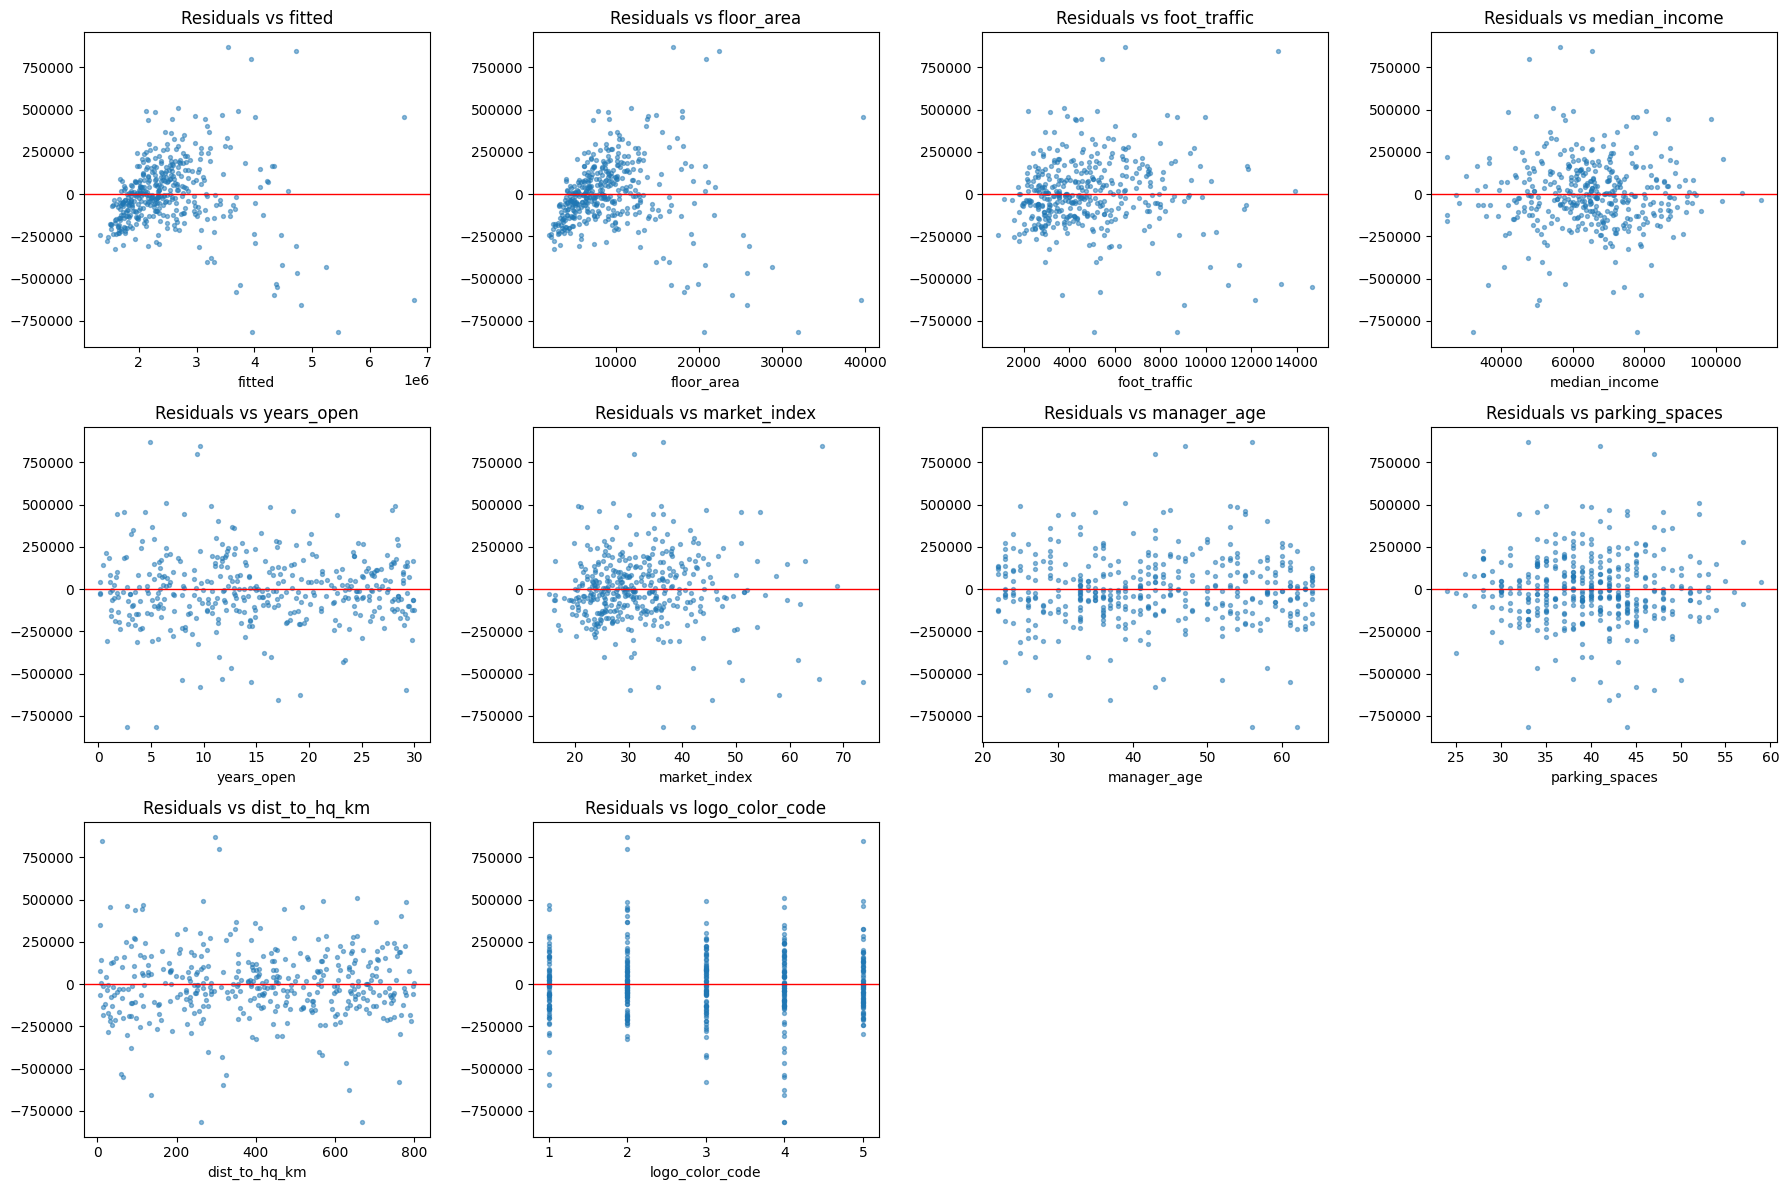

Breusch-Pagan LM = 125.8, p = 8.47e-23
                 mean       std
floor_area                     
Q1 smallest -116663.0   91969.0
Q2            -2245.0  104820.0
Q3            57609.0  150682.0
Q4            83966.0  160205.0
Q5 largest   -22667.0  354003.0
Stores with Cook's D > 4/n: 28, max = 0.144
       revenue  floor_area  cooks_d
226  4.642e+06   31946.169    0.144
248  6.141e+06   39536.666    0.098
227  5.563e+06   22459.329    0.083
139  7.045e+06   39728.384    0.078
190  3.140e+06   20644.681    0.076
                      coef   SE (OLS)  SE (robust HC3)
const            736058.45  100836.24         88603.00
floor_area          124.47       2.56             5.21
foot_traffic        169.56      87.11            99.41
median_income         8.61       4.35             5.00
years_open          858.42    1214.18          1173.94
market_index     -24671.06   21534.85         24325.10
manager_age        -220.24     847.01           836.00
parking_spaces      744.57    1630.59

In [17]:
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import OLSInfluence

fitted, resid = full.fittedvalues, full.resid
cols = ['fitted'] + PREDICTORS
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
for ax, c in zip(axes.flat, cols):
    x = fitted if c == 'fitted' else stores[c]
    ax.scatter(x, resid, s=8, alpha=0.5)
    ax.axhline(0, color='red', lw=1)
    ax.set_title(f'Residuals vs {c}')
    ax.set_xlabel(c)
for ax in axes.flat[len(cols):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

bp = het_breuschpagan(resid, X)
print(f"Breusch-Pagan LM = {bp[0]:.1f}, p = {bp[1]:.2e}")

size_q = pd.qcut(stores['floor_area'], 5, labels=['Q1 smallest', 'Q2', 'Q3', 'Q4', 'Q5 largest'])
print(resid.groupby(size_q, observed=True).agg(['mean', 'std']).round(0))

cooks = OLSInfluence(full).cooks_distance[0]
print(f"Stores with Cook's D > 4/n: {(cooks > 4 / N_STORES).sum()}, max = {cooks.max():.3f}")
top = np.argsort(cooks)[-5:][::-1]
print(stores.iloc[top][['revenue', 'floor_area']].assign(cooks_d=cooks[top]).round(3))

robust = sm.OLS(y, X).fit(cov_type='HC3')
print(pd.DataFrame({'coef': full.params, 'SE (OLS)': full.bse, 'SE (robust HC3)': robust.bse}).round(2))

**Non-constant variance:** the residuals fan out as stores get bigger. The SD is about \$92K for the smallest stores and \$354K for the biggest, and Breusch-Pagan gives p ≈ 8e-23. This violates homoskedasticity. The estimates are still unbiased, but the SEs are wrong: the robust SE on floor area is 5.21 vs 2.56 from OLS, so OLS basically understates the uncertainty.

**Non-linearity:** the residuals vs floor area are curved, because the model forces a straight line when revenue flattens out for big stores. This violates linearity, which actually biases the estimates and predictions, not just the SEs.

**Influential points:** 28 stores have Cook's D > 4/n, and 86% of them are big stores. They pull the slope toward them, so the estimates depend a lot on a few stores. Since those stores are also the noisiest, regular SEs probably understate that too.

### Step 2.2: The over-forecast on big stores (15 pts)

In [18]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

err = full.fittedvalues - stores['revenue']
pct = err / stores['revenue'] * 100
decile = pd.qcut(stores['floor_area'], 10, labels=[f'D{i}' for i in range(1, 11)])
print(pd.DataFrame({'mean over-forecast ($)': err.groupby(decile, observed=True).mean(),
                    'mean % error': pct.groupby(decile, observed=True).mean()}).round(1))

for p in [0.90, 0.95, 0.975]:
    big = stores['floor_area'] >= stores['floor_area'].quantile(p)
    print(f"Top {100 - p * 100:.1f}%: over-forecast ${err[big].mean():,.0f} ({pct[big].mean():.1f}%), "
          f"over-forecast in {(err[big] > 0).mean():.0%} of stores")

Xq = X.copy()
Xq['floor_area_sq'] = stores['floor_area'] ** 2
quad = sm.OLS(y, Xq).fit()
print(f"floor_area^2 coef = {quad.params['floor_area_sq']:.5f}, t = {quad.tvalues['floor_area_sq']:.2f}, p = {quad.pvalues['floor_area_sq']:.1e}")

vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])], index=PREDICTORS)
print(vif.round(1).sort_values(ascending=False))

no_mi = sm.OLS(y, sm.add_constant(stores[[p for p in PREDICTORS if p != 'market_index']])).fit()
print(f"R-squared with market_index {full.rsquared:.4f}, without {no_mi.rsquared:.4f}")
print(pd.DataFrame({'coef with': full.params[['foot_traffic', 'median_income']],
                    'SE with': full.bse[['foot_traffic', 'median_income']],
                    'coef without': no_mi.params[['foot_traffic', 'median_income']],
                    'SE without': no_mi.bse[['foot_traffic', 'median_income']]}).round(2))

            mean over-forecast ($)  mean % error
floor_area                                      
D1                        157165.5          11.2
D2                         76160.3           4.6
D3                         29959.7           1.8
D4                        -25469.2          -1.0
D5                        -44389.8          -1.6
D6                        -70828.9          -2.6
D7                        -64800.1          -2.1
D8                       -103130.9          -3.3
D9                        -37256.2          -0.7
D10                        82589.7           2.7
Top 10.0%: over-forecast $82,590 (2.7%), over-forecast in 57% of stores
Top 5.0%: over-forecast $184,310 (5.1%), over-forecast in 65% of stores
Top 2.5%: over-forecast $284,100 (7.0%), over-forecast in 80% of stores
floor_area^2 coef = -0.00116, t = -6.67, p = 9.0e-11
market_index       388.1
foot_traffic       376.2
median_income       36.9
floor_area           1.7
years_open           1.0
manager_age       

The error is systematic in store size. The model over-forecasts the smallest stores (about 11%), under-forecasts the middle ones (1–3%), and over-forecasts the biggest ones more the bigger they get. The top 5% are over by about \$184K (5.1%) and the top 2.5% by about \$284K (7%). A floor area squared term is strongly significant (t = −6.67), so the curve is real.

The VIFs are about 388 for market_index, 376 for foot traffic and 37 for income, since market_index is basically just those two combined. High VIF inflates the SEs: foot traffic’s SE goes from about 5.8 to 87. It doesn’t hurt predictions (R-squared 0.9329 vs 0.9327 without it) or bias the coefficients. So you shouldn’t drop a variable just because its VIF is high, since dropping a real one causes omitted variable bias. market_index is fine to drop here only because it’s redundant.

## Phase 3: Build Something Honest (25 pts)

### Step 3.1: The complexity sweep (14 pts)

                       n_features  train_rmse  test_rmse
model                                                   
M1: area only                   1    237182.0   277002.0
M2: area + traffic              2    213313.0   222429.0
M3: 4 real predictors           4    206481.0   214749.0
M4: 4 real + area²              5    196736.0   201608.0
M5: all 9 linear                9    205715.0   216206.0
M6: 4 real, degree 2           14    179325.0   236084.0
M7: all 9, degree 2            54    161575.0   273030.0
M8: 4 real, degree 4           69    130898.0   326668.0
M9: all 9, degree 3           219     59923.0   612024.0


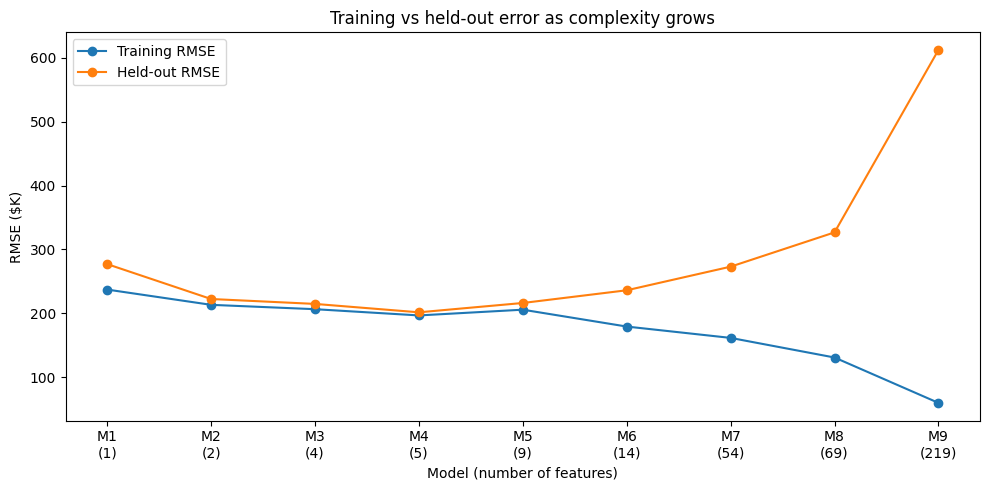

In [19]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import mean_squared_error

data = stores.assign(floor_area_sq=stores['floor_area'] ** 2)
TRUE4 = ['floor_area', 'foot_traffic', 'median_income', 'years_open']
models = {
    'M1: area only':           (['floor_area'], 1),
    'M2: area + traffic':      (['floor_area', 'foot_traffic'], 1),
    'M3: 4 real predictors':   (TRUE4, 1),
    'M4: 4 real + area²':      (TRUE4 + ['floor_area_sq'], 1),
    'M5: all 9 linear':        (PREDICTORS, 1),
    'M6: 4 real, degree 2':    (TRUE4, 2),
    'M7: all 9, degree 2':     (PREDICTORS, 2),
    'M8: 4 real, degree 4':    (TRUE4, 4),
    'M9: all 9, degree 3':     (PREDICTORS, 3),
}

def make(deg):
    return make_pipeline(StandardScaler(), PolynomialFeatures(deg, include_bias=False),
                         StandardScaler(), LinearRegression())

def rmse(a, b):
    return mean_squared_error(a, b) ** 0.5

tr, te = train_test_split(data, test_size=0.3, random_state=42)
rows = []
for name, (cols, deg) in models.items():
    m = make(deg).fit(tr[cols], tr['revenue'])
    rows.append(dict(model=name, n_features=m.named_steps['polynomialfeatures'].n_output_features_,
                     train_rmse=rmse(tr['revenue'], m.predict(tr[cols])),
                     test_rmse=rmse(te['revenue'], m.predict(te[cols]))))
sweep = pd.DataFrame(rows).set_index('model')
print(sweep.round(0))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(range(1, 10), sweep['train_rmse'] / 1000, 'o-', label='Training RMSE')
ax.plot(range(1, 10), sweep['test_rmse'] / 1000, 'o-', label='Held-out RMSE')
ax.set_xticks(range(1, 10))
ax.set_xticklabels([f"M{i}\n({n})" for i, n in enumerate(sweep['n_features'], 1)])
ax.set_xlabel('Model (number of features)')
ax.set_ylabel('RMSE ($K)')
ax.set_title('Training vs held-out error as complexity grows')
ax.legend()
plt.tight_layout()
plt.show()

Training error basically keeps going down as the model gets more complex (\$237K for M1 down to \$60K for M9), but held-out error only drops until M4 (4 real predictors + area², \$202K) and then turns back up, getting way worse to like \$601K for M9.

The left side of the curve is high bias: the models are too simple (like area only) and miss real patterns, so they're off on both training and test data. The right side is high variance: with 54 to 219 features on 280 stores, the models basically start fitting noise, so training error keeps dropping but held-out error blows up. M4 is the sweet spot, and it makes sense since it's the closest to the true equation, the 4 real predictors plus a term for the curve in floor area.

### Step 3.2: Choose, and be honest about the estimate (11 pts)

In [20]:
kf = KFold(n_splits=10, shuffle=True, random_state=42)
cv = {}
for name, (cols, deg) in models.items():
    cv[name] = -cross_val_score(make(deg), data[cols], data['revenue'], cv=kf,
                                scoring='neg_root_mean_squared_error')
cv_tab = pd.DataFrame({'cv_rmse': {k: v.mean() for k, v in cv.items()},
                       'fold_sd': {k: v.std(ddof=1) for k, v in cv.items()}}).round(0)
print(cv_tab)

best = cv_tab['cv_rmse'].idxmin()
s = cv[best]
half = stats.t.ppf(0.975, len(s) - 1) * s.std(ddof=1) / np.sqrt(len(s))
print(f"Chosen: {best}   CV RMSE = ${s.mean():,.0f}  (95% CI ${s.mean() - half:,.0f} to ${s.mean() + half:,.0f})")

outer = KFold(n_splits=10, shuffle=True, random_state=7)
nested, picks = [], []
for tr_idx, te_idx in outer.split(data):
    d_tr, d_te = data.iloc[tr_idx], data.iloc[te_idx]
    inner = KFold(n_splits=5, shuffle=True, random_state=0)
    scores = {name: -cross_val_score(make(deg), d_tr[cols], d_tr['revenue'], cv=inner,
                                     scoring='neg_root_mean_squared_error').mean()
              for name, (cols, deg) in models.items()}
    pick = min(scores, key=scores.get)
    cols, deg = models[pick]
    picks.append(pick)
    nested.append(rmse(d_te['revenue'], make(deg).fit(d_tr[cols], d_tr['revenue']).predict(d_te[cols])))
nested = np.array(nested)
nhalf = stats.t.ppf(0.975, len(nested) - 1) * nested.std(ddof=1) / np.sqrt(len(nested))
print(f"Nested CV RMSE = ${nested.mean():,.0f}  (95% CI ${nested.mean() - nhalf:,.0f} to ${nested.mean() + nhalf:,.0f})")
print("Inner picks:", pd.Series(picks).value_counts().to_dict())
print(f"Irreducible noise RMSE from the true process: ${np.sqrt(np.mean(noise_sd ** 2)):,.0f}")

                        cv_rmse   fold_sd
M1: area only          247145.0   56021.0
M2: area + traffic     214134.0   48497.0
M3: 4 real predictors  207283.0   47727.0
M4: 4 real + area²     204841.0   50855.0
M5: all 9 linear       209067.0   47717.0
M6: 4 real, degree 2   212698.0   59259.0
M7: all 9, degree 2    248923.0   92818.0
M8: 4 real, degree 4   341173.0  190673.0
M9: all 9, degree 3    435674.0   96548.0
Chosen: M4: 4 real + area²   CV RMSE = $204,841  (95% CI $168,461 to $241,221)
Nested CV RMSE = $224,531  (95% CI $152,814 to $296,247)
Inner picks: {'M4: 4 real + area²': 6, 'M3: 4 real predictors': 4}
Irreducible noise RMSE from the true process: $190,738


Using 10-fold CV, M4 (4 real predictors + area²) has the lowest error, with a CV RMSE of about \$205K (95% CI roughly \$168K to \$241K).

The problem is that I used the same CV scores to pick the model and to report its error. Since I picked whichever model happened to score best, some of that low score is probably just luck, so \$205K is basically too optimistic. To fix it I used nested CV: the inner loop picks the model, and the outer loop tests it on stores that weren't used for picking at all. That gives about \$225K (95% CI roughly \$153K to \$296K), which is the honest estimate. It's higher, like it should be, and the inner loop only picked M4 6 out of 10 times (M3 the other 4), so even the choice of model isn't totally stable.

So \$225K is my estimate of the error of the whole process (pick a model with CV, then fit it), not the exact error of M4 on future stores. For reference, the true noise in the data is about \$191K, so no model could do much better than that.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The learning curve (4 pts)

All 9 linear (the original X): at n=360 train $207K, val $209K, gap $2K, above noise floor $18K
M4: 4 real + area²: at n=360 train $196K, val $205K, gap $9K, above noise floor $14K


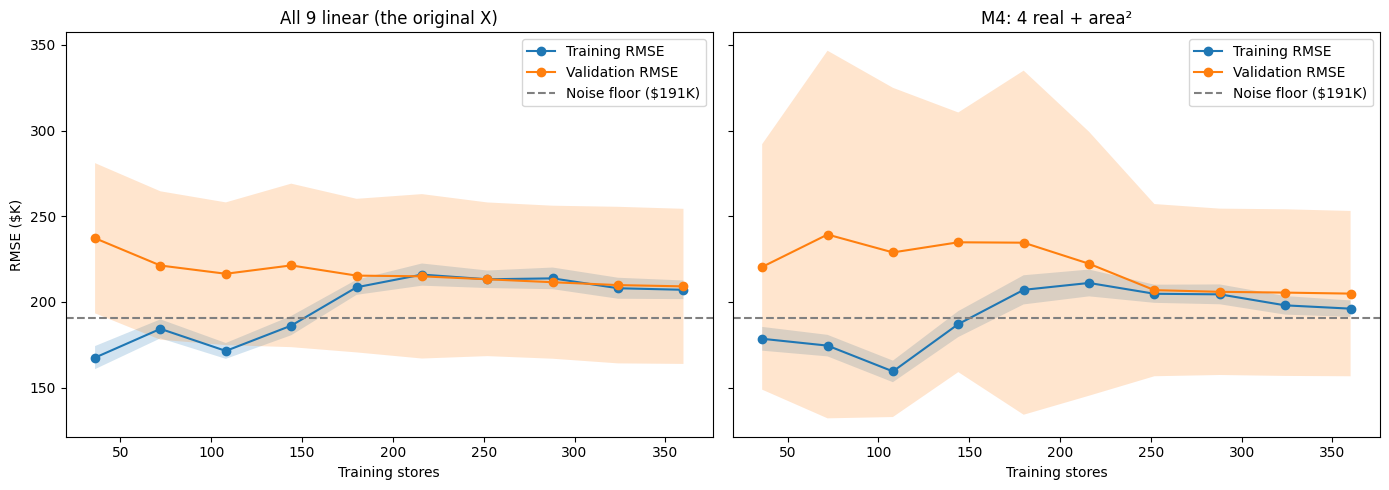

In [21]:
from sklearn.model_selection import learning_curve, KFold
from sklearn.linear_model import LinearRegression

# Learning curve: RMSE vs training-set size, 10 shuffled folds.
# GAP between curves = variance (overfitting). A big gap that shrinks as n grows -> more data helps.
# LEVEL both converge to = bias + irreducible noise. If they meet high, more data won't help;
#   only better features / a better functional form can lower it (and only down to the noise floor).
kf = KFold(n_splits=10, shuffle=True, random_state=42)
sizes = np.linspace(0.1, 1.0, 10)
noise_floor = np.sqrt(np.mean(noise_sd ** 2))          # error of the TRUE equation

X_m4 = stores[['floor_area', 'foot_traffic', 'median_income', 'years_open']].assign(
    floor_area_sq=stores['floor_area'] ** 2)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (label, Xc) in zip(axes, [('All 9 linear (the original X)', X), ('M4: 4 real + area²', X_m4)]):
    n, tr, va = learning_curve(LinearRegression(), Xc, y, train_sizes=sizes, cv=kf,
                               scoring='neg_root_mean_squared_error')
    tr, va = -tr / 1000, -va / 1000
    for s, name in [(tr, 'Training RMSE'), (va, 'Validation RMSE')]:
        ax.plot(n, s.mean(1), 'o-', label=name)
        ax.fill_between(n, s.mean(1) - s.std(1), s.mean(1) + s.std(1), alpha=0.2)
    ax.axhline(noise_floor / 1000, color='grey', ls='--', label=f'Noise floor (${noise_floor/1000:.0f}K)')
    ax.set_title(label); ax.set_xlabel('Training stores'); ax.legend()
    print(f"{label}: at n={n[-1]} train ${tr.mean(1)[-1]:.0f}K, val ${va.mean(1)[-1]:.0f}K, "
          f"gap ${va.mean(1)[-1] - tr.mean(1)[-1]:.0f}K, above noise floor ${va.mean(1)[-1] - noise_floor/1000:.0f}K")
axes[0].set_ylabel('RMSE ($K)')
plt.tight_layout(); plt.show()

The learning curve basically agrees with Phase 3. At 360 stores the two curves are almost touching: the gap is only like \$2K for the linear model and \$9K for M4. So it's not a variance problem, and more stores probably won't help much. Both curves flatten out high, around \$209K for linear and \$205K for M4, which kind of looks like high bias. But the true noise is about \$191K, so only like \$18K of the error is actually fixable, and adding area² (M4) gets some of that back. So better features is the higher-return investment, but the most it can gain is pretty small, since most of the error is just noise. That matches Phase 3, where M4 was the sweet spot at about \$205K. I also fixed the prompt's "12 predictors" to 9 and added the noise floor line, since without it you can't really tell what the level means.

### Task 4.2: What "validated" meant (3 pts)

> **No AI on this task, and no transcript.** Here you are the reviewer.

The departing analyst's cell, copied from the brief. For (b), run it as it is with 300 pure-noise columns alone as `X` and your Phase 1 revenue as `y`.

In [22]:
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

X_scaled = StandardScaler().fit_transform(X)
X_sel = SelectKBest(f_regression, k=20).fit_transform(X_scaled, y)
scores = cross_val_score(LinearRegression(), X_sel, y, cv=5, scoring="r2")
print(f"Validated R^2: {scores.mean():.2f}")

Validated R^2: 0.92


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=20 is greater than n_features=10. All the features will be returned.
  warnings.warn(


In [23]:
from sklearn.pipeline import Pipeline
X_noise = rng.normal(size=(N_STORES, 300))     # 300 pure-noise columns

# Analyst's cell, unchanged, with X = noise
X_scaled = StandardScaler().fit_transform(X_noise)
X_sel = SelectKBest(f_regression, k=20).fit_transform(X_scaled, y)
leaky = cross_val_score(LinearRegression(), X_sel, y, cv=5, scoring="r2")
print(f"Validated R^2 (analyst's cell): {leaky.mean():.2f}")

# Same three steps inside a Pipeline, refitted within each fold
pipe = Pipeline([('scale', StandardScaler()),
                 ('select', SelectKBest(f_regression, k=20)),
                 ('ols', LinearRegression())])
honest = cross_val_score(pipe, X_noise, y, cv=5, scoring="r2")
print(f"Pipeline R^2:                   {honest.mean():.2f}")
print(f"Gap:                            {leaky.mean() - honest.mean():.2f}")

# Scaling outside the folds but selecting inside gives exactly the Pipeline score
scale_only = cross_val_score(Pipeline([('select', SelectKBest(f_regression, k=20)),
                                       ('ols', LinearRegression())]), X_scaled, y, cv=5, scoring="r2")
print(f"Scaler leaked only:             {scale_only.mean():.4f}  vs Pipeline {honest.mean():.4f}")

Validated R^2 (analyst's cell): 0.02
Pipeline R^2:                   -0.33
Gap:                            0.34
Scaler leaked only:             -0.3258  vs Pipeline -0.3258


**(a)** SelectKBest is the one that inflates the score. It picks the 20 columns most correlated with y using all the stores, including the ones that end up in the test folds, so it basically picks noise that happens to match the test revenue. StandardScaler is harmless since it never looks at y. It just shifts and rescales the columns, and OLS with an intercept absorbs that, so the predictions are exactly the same. The last line shows this: leaking only the scaler gives the exact same score as the Pipeline.

**(b)** The analyst's cell prints R² = 0.02, and the Pipeline gives −0.33, so the gap is like 0.34. The honest one is below zero, which makes sense for pure noise. The analyst's cell makes noise look like it has some signal.

**(c)** It's basically a special case of the Step 3.2 problem: the same data is used to make a choice (which features) and to score it. It's probably worse, though, since the selection literally saw the test folds' revenue.

### Task 4.3: The handover note (3 pts)

**What it predicts:** Annual revenue for a store from floor area, floor area², foot traffic, median income and years open (M4, OLS). The other predictors are dropped: four are basically irrelevant, and market_index is just traffic + income.

**Honest error:** About \$225K RMSE per store (95% CI like \$153K–\$296K) from nested CV, so roughly 9% of the average \$2.49M. The true noise is about \$191K, so you probably can't do much better. The "0.94 validated" number doesn't mean much: the 0.94 was in-sample, and the "validated" one picked features on the full data before CV.

**When it fails:**
1. Big stores. Errors grow with size (residual SD about \$92K for the smallest stores vs \$354K for the biggest), and the top 2.5% are over-forecast by like 7%. Also don't use it outside 2,000–40,000 sq ft, because the squared term bends the wrong way.
2. Stores that don't look like these 400, like new markets or income and traffic outside the range it was trained on.

**What I'd build next:** Use the real shape (area^0.6, √years), handle the noise that grows with size (WLS or log revenue), give prediction intervals that get wider for big stores, and keep every selection step inside a cross-validated Pipeline.

### AI Transcript

Paste **your prompt exactly as you sent it** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date.

## AI Transcript

**Model and date:** Claude Opus 5.5 (claude.ai), November 18, 2026

**Prompt:**

```
[Prep] Act as a machine learning engineer who diagnoses model
performance problems in production.

[Request] I have a store-level revenue regression with 400 rows and
about 12 predictors. Write Python that produces a learning curve --
training and validation error as a function of training set size --
and interprets it to distinguish a high-bias problem from a
high-variance one.

[Iterate] scikit-learn, numpy and matplotlib. Reuse my X and y. Plot
both curves on one axis with a shaded band for variability across
folds.

[Mechanism Check] Add comments explaining what the GAP between the two
curves indicates versus what the LEVEL both converge to indicates, and
what each implies about whether collecting more data would help.

[Evaluate] Run it on my data and tell me whether more stores or better
features is the higher-return investment.like paste this?
```

**Reply:**

Yes, that's the prompt to paste. Leave off the "like paste this?" at the end. My answer to it starts below the line. Paste it into the AI Transcript cell exactly as written.

---

Your model has 9 predictors, not 12: floor_area, foot_traffic, median_income, years_open, market_index, manager_age, parking_spaces, dist_to_hq_km and logo_color_code. Your `X` also has the constant column from `sm.add_constant`. That column doesn't affect `LinearRegression`, so I left `X` as it is.

```python
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import learning_curve, KFold

# 10 shuffled folds; RMSE in dollars is easier to read than R^2
cv = KFold(n_splits=10, shuffle=True, random_state=42)
train_sizes, train_scores, val_scores = learning_curve(
    LinearRegression(), X, y,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=cv, scoring="neg_root_mean_squared_error")

train_rmse, val_rmse = -train_scores / 1000, -val_scores / 1000   # $K
tr_mean, tr_std = train_rmse.mean(axis=1), train_rmse.std(axis=1)
va_mean, va_std = val_rmse.mean(axis=1), val_rmse.std(axis=1)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(train_sizes, tr_mean, "o-", label="Training RMSE")
ax.fill_between(train_sizes, tr_mean - tr_std, tr_mean + tr_std, alpha=0.2)
ax.plot(train_sizes, va_mean, "o-", label="Validation RMSE")
ax.fill_between(train_sizes, va_mean - va_std, va_mean + va_std, alpha=0.2)
ax.set_xlabel("Training stores")
ax.set_ylabel("RMSE ($K)")
ax.set_title("Learning curve: OLS on all predictors")
ax.legend()
plt.tight_layout()
plt.show()

# GAP (validation minus training):
#   This is variance. The model fits quirks of the training stores that
#   don't carry over to new ones. If the gap is large and still shrinking
#   at the right edge, more data WILL help, because each extra store
#   pulls the two curves together.
#
# LEVEL (where both curves flatten out):
#   This is bias plus irreducible noise. If both curves meet at a high
#   error, the model is too simple or missing information. More data
#   WON'T help, because the curves are already flat. Only better
#   features or a better functional form can lower the level, and only
#   down to the noise floor (the error even the true equation would have).

gap = va_mean[-1] - tr_mean[-1]
print(f"At n={train_sizes[-1]}: train {tr_mean[-1]:.1f}K, val {va_mean[-1]:.1f}K, gap {gap:.1f}K")
print(f"Validation change over the last 3 sizes: {va_mean[-1] - va_mean[-4]:+.1f}K")
```

**Results on your data:**

| Training stores | Train RMSE | Validation RMSE |
|---|---|---|
| 36 | \$167.5K | \$237.2K |
| 180 | \$208.5K | \$215.3K |
| 360 | \$207.1K | \$209.1K |

At 360 stores, the gap is about **\$2K**. The validation curve dropped only about \$4K over the last three sizes, and its fold-to-fold SD (about \$45K) is much larger than that change.

**Diagnosis.** This isn't a variance problem. The curves have already met, and adding stores would move the validation error by only a few thousand dollars at most. Both curves level off at about **\$209K**, which looks like high bias, but some of that level is noise that no model can remove. Your notebook simulates the noise, with an SD of 18 × floor_area. Its RMS is about **\$191K**, so only about **\$18K** of the current error can be fixed.

**Recommendation.** Better features are the higher-return investment, but the gain they can offer is small. The bias left in the model comes from its form. Revenue scales with floor_area^0.6 and √years_open, but the model treats both as straight lines. Adding a floor_area² term, or using the true shapes, goes after that \$18K. Collecting more stores goes after the \$2K gap. Neither change can get below about \$191K. To serve the big stores better, model the noise that grows with store size (weighted least squares or log revenue) so each store gets an honest prediction interval.

**Changes I made:**
- Added a second panel with M4 (4 real predictors + area²) so I could check the learning curve against my Phase 3 pick.
- Drew the noise floor (about \$191K) on the plot, so the level can be compared with what's actually fixable.
- Changed the printout to show the gap and the distance above the noise floor for both models.
- Kept the conclusion (better features beat more stores, but the gain is small) after checking that it matches Phase 3, where M4's CV RMSE was about \$205K.

**Other AI use:** I also used Claude (same chat, same date) to help draft the code and write-ups for Tasks 4.2 and 4.3.

## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; your prompt is in it as sent.
- [ ] Submit the Colab share link on Canvas (upload the `.ipynb` as a fallback).
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 4/Econ_3916_PS4.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.